# Employee Salary Prediction Using Machine Learning

## 1. Business Problem

The Human Resources department needs to maintain a fair and consistent salary range for employees with similar profiles. Salary decisions may depend on factors such as experience, skills, education, role, department, and other applicant characteristics. This project uses historical applicant data to build a machine learning model that predicts the salary/CTC to be offered to a selected candidate.

## 2. Objective

The main objective of this project is to develop a machine learning model that predicts the Expected CTC of a prospective employee using historical applicant data. The model aims to reduce manual judgment and support consistent and data-driven salary decisions.

## 3. Dataset

The dataset contains information about candidates who applied to Company X. It includes numerical and categorical attributes related to the applicants. The target variable used for prediction is Expected_CTC.

## 4. Technologies Used

* Python
* Pandas
* NumPy
* Matplotlib
* Scikit-learn
* Google Colab / Anaconda

## 5. Machine Learning Algorithm

Random Forest Regressor is used for predicting the Expected CTC. Random Forest is an ensemble machine learning algorithm that combines multiple decision trees to produce a reliable prediction.

## 6. Methodology

1. Load the dataset.
2. Explore the dataset.
3. Check and handle missing values.
4. Remove unnecessary ID columns.
5. Convert categorical variables into numerical values.
6. Divide the data into training and testing sets.
7. Train the Random Forest Regression model.
8. Predict Expected CTC for the test data.
9. Evaluate the model using MAE, MSE, RMSE, and R² Score.
10. Visualize actual and predicted CTC values.

## 7. Evaluation Metrics

### MAE

Mean Absolute Error measures the average absolute difference between the actual and predicted CTC values.

### MSE

Mean Squared Error measures the average squared difference between actual and predicted values.

### RMSE

Root Mean Squared Error represents the prediction error in the same unit as the target variable.

### R² Score

R² Score indicates how well the model explains the variation in Expected CTC. A value closer to 1 generally indicates better model performance.

## 8. Result

The Random Forest Regression model was trained using historical applicant data and used to predict Expected CTC.

The obtained performance metrics are:

MAE: [Enter your Colab output]

MSE: [Enter your Colab output]

RMSE: [Enter your Colab output]

R² Score: [Enter your Colab output]

The Actual vs Predicted CTC graph was also generated to visually evaluate the model's predictions.

## 9. Conclusion

This project demonstrates the use of machine learning for employee salary prediction. The Random Forest Regression model can predict the Expected CTC based on applicant characteristics. A data-driven approach can help reduce dependence on manual judgment and support more consistent salary recommendations for candidates with similar profiles.

## 10. Future Enhancement

* Compare different regression algorithms.
* Perform hyperparameter tuning to improve model performance.
* Add fairness and bias analysis to evaluate salary recommendations.
* Develop a web application for HR users.
* Allow HR users to enter candidate details and obtain a predicted CTC.


In [7]:
import pandas as pd
import numpy as np


df = pd.read_csv("/content/expected_ctc.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Shape: (25000, 29)
   IDX  Applicant_ID  Total_Experience  Total_Experience_in_field_applied  \
0    1         22753                 0                                  0   
1    2         51087                23                                 14   
2    3         38413                21                                 12   
3    4         11501                15                                  8   
4    5         58941                10                                  5   

       Department               Role   Industry Organization      Designation  \
0             NaN                NaN        NaN          NaN              NaN   
1              HR         Consultant  Analytics            H               HR   
2  Top Management         Consultant   Training            J              NaN   
3         Banking  Financial Analyst   Aviation            F               HR   
4           Sales    Project Manager  Insurance            E  Medical Officer   

  

In [8]:
print(df.columns.tolist())

['IDX', 'Applicant_ID', 'Total_Experience', 'Total_Experience_in_field_applied', 'Department', 'Role', 'Industry', 'Organization', 'Designation', 'Education', 'Graduation_Specialization', 'University_Grad', 'Passing_Year_Of_Graduation', 'PG_Specialization', 'University_PG', 'Passing_Year_Of_PG', 'PHD_Specialization', 'University_PHD', 'Passing_Year_Of_PHD', 'Curent_Location', 'Preferred_location', 'Current_CTC', 'Inhand_Offer', 'Last_Appraisal_Rating', 'No_Of_Companies_worked', 'Number_of_Publications', 'Certifications', 'International_degree_any', 'Expected_CTC']


In [9]:
# Remove ID columns
df = df.drop(columns=['IDX', 'Applicant_ID'], errors='ignore')

# Remove rows where target is missing
df = df.dropna(subset=['Expected_CTC'])

print("Shape after cleaning:", df.shape)
print("Missing values in target:", df['Expected_CTC'].isnull().sum())

Shape after cleaning: (25000, 27)
Missing values in target: 0


In [10]:
X = df.drop(columns=['Expected_CTC'])
y = df['Expected_CTC']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (25000, 26)
y shape: (25000,)


In [11]:
# Convert categorical/text columns into numbers
X = pd.get_dummies(X, dummy_na=True)

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values
X = X.fillna(0)

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

Final X shape: (25000, 220)
Final y shape: (25000,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (20000, 220)
Testing data: (5000, 220)


In [13]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training started...")

model.fit(X_train, y_train)

print("Training completed successfully!")

Training started...
Training completed successfully!


In [14]:
y_pred = model.predict(X_test)

print("Prediction completed!")
print(y_pred[:10])

Prediction completed!
[3105689.95 1251256.28 3621235.46 2760174.41 1051194.38 2203567.94
 1288405.54 2318375.42 3290117.69  626377.73]


In [15]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("==============================")
print("MODEL PERFORMANCE")
print("==============================")

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)

MODEL PERFORMANCE
MAE  : 9692.179345999997
MSE  : 443522517.6100412
RMSE : 21059.97430221702
R2 Score : 0.9996720663258367


In [16]:
results = pd.DataFrame({
    'Actual_CTC': y_test.values,
    'Predicted_CTC': y_pred
})

print(results.head(20))

    Actual_CTC  Predicted_CTC
0      3113073     3105689.95
1      1263089     1251256.28
2      3638037     3621235.46
3      2759980     2760174.41
4      1040303     1051194.38
5      2208350     2203567.94
6      1281873     1288405.54
7      2322435     2318375.42
8      3219206     3290117.69
9       650182      626377.73
10     2776168     2755391.26
11     5157044     5158373.11
12     2643952     2644814.83
13     1762531     1763610.09
14      551127      547633.80
15     1372864     1344990.68
16     1529465     1533360.93
17     2996175     3000037.85
18      321441      388978.12
19     2097685     2097986.61


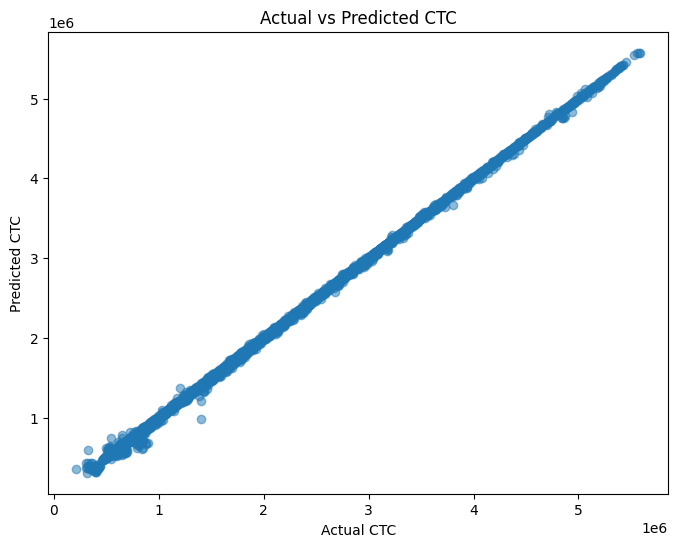

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual CTC")
plt.ylabel("Predicted CTC")
plt.title("Actual vs Predicted CTC")

plt.show()

In [20]:
results.to_csv(
    'salary_predictions.csv',
    index=False
)

print("salary_predictions.csv created successfully!")

salary_predictions.csv created successfully!
